In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
TRK_FILE = r"track_amazon_lluc/tracking_table/monthly/*.parquet"

con = duckdb.connect("tracking_analysis.duckdb")

january_by_year = con.execute(f"""
    WITH uid_duration AS (
        SELECT uid, MIN(timestamp) AS first_timestamp, MAX(duration) / 60.0 AS duration_hr
        FROM read_parquet('{TRK_FILE}', union_by_name = true)
        WHERE uid IS NOT NULL
          AND timestamp >= TIMESTAMP '2001-01-01'
          AND duration IS NOT NULL
          AND isfinite(duration)
        GROUP BY uid)

    SELECT YEAR(first_timestamp) AS year, duration_hr
    FROM uid_duration
    WHERE MONTH(first_timestamp) = 1
      AND duration_hr >= 0
    ORDER BY year
""").fetchdf()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [2]:
TRK_FILE = r"track_amazon_lluc/tracking_table/monthly/*.parquet"

con = duckdb.connect("tracking_analysis.duckdb")

monthly_duration = con.execute(f"""
WITH uid_duration AS (
    SELECT uid, MIN(timestamp) AS first_timestamp, MAX(duration) / 60.0 AS duration_hr
    FROM read_parquet('{TRK_FILE}', union_by_name = true)
    WHERE uid IS NOT NULL
      AND timestamp >= TIMESTAMP '2001-01-01'
      AND duration IS NOT NULL
      AND isfinite(duration)
    GROUP BY uid
)
SELECT YEAR(first_timestamp) AS year, MONTH(first_timestamp) AS month, duration_hr
FROM uid_duration
WHERE duration_hr > 0
  AND YEAR(first_timestamp) <= 2024
""").fetchdf()

IOException: IO Error: Cannot open file "C:\Users\ADM\Documents\tracking\tracking_analysis.duckdb": O arquivo já está sendo usado por outro processo.

File is already open in 
C:\Users\ADM\miniconda3\envs\tracking\python.exe (PID 26888)

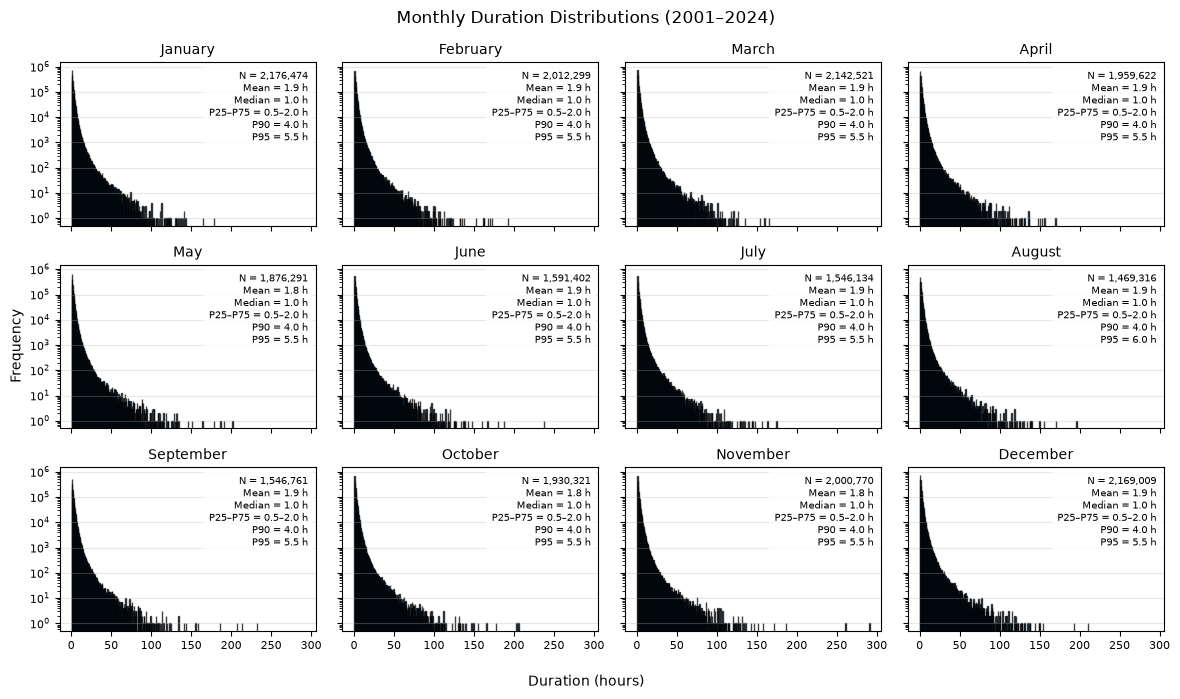

In [ ]:
months = range(1, 13)
month_names = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
bins = np.arange(0, monthly_duration["duration_hr"].max() + 0.5, 0.5)

fig, axes = plt.subplots(3, 4, figsize=(12, 7), sharex=True, sharey=True)
for ax, month, name in zip(axes.flatten(), months, month_names):
    values = monthly_duration.loc[monthly_duration["month"] == month, "duration_hr"].dropna()
    frequency, bin_edges = np.histogram(values, bins=bins)
    centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    bin_width = bin_edges[1] - bin_edges[0]
    ax.bar(centers, frequency, width=bin_width, edgecolor="black", alpha=0.75)

    # Statistics
    p25 = values.quantile(0.25)
    p75 = values.quantile(0.75)
    p90 = values.quantile(0.90)
    p95 = values.quantile(0.95)
    
    stats_text = (
        f"N = {len(values):,}\n"
        f"Mean = {values.mean():.1f} h\n"
        f"Median = {values.median():.1f} h\n"
        f"P25–P75 = {p25:.1f}–{p75:.1f} h\n"
        f"P90 = {p90:.1f} h\n"
        f"P95 = {p95:.1f} h")

    ax.text(0.97, 0.95, stats_text, transform=ax.transAxes, fontsize=7, verticalalignment="top", horizontalalignment="right", bbox=dict(facecolor="white", edgecolor="none", alpha=0.85))
    ax.set_title(name, fontsize=10)
    ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="both", labelsize=8)

fig.supxlabel("Duration (hours)", fontsize=10)
fig.supylabel("Frequency", fontsize=10)
fig.suptitle("Monthly Duration Distributions (2001–2024)", fontsize=12)

plt.tight_layout()
plt.show()